# Chapitre 6 - Cours 1 : découper les données, par plage de clés ou par hachage

Quand le volume de données ou le débit de requêtes dépasse ce qu'une machine peut
absorber, on découpe le jeu de données en morceaux, les **partitions**, et l'on place des
partitions différentes sur des nœuds différents. Chaque enregistrement appartient à une
seule partition ; chaque partition est en quelque sorte une petite base autonome. Le but
premier est la **scalabilité** : répartir données et requêtes sur de nombreux disques et
processeurs. Ce notebook couvre l'introduction du chapitre (avec l'encadré
*Terminological confusion*), la section *Partitioning and Replication* et la section
*Partitioning of Key-Value Data* jusqu'aux sous-sections *Partitioning by Key Range* et
*Partitioning by Hash of Key* (le rééquilibrage fait l'objet du cours 2).

**Plan.**

1. Partitionnement et réplication : deux mécanismes indépendants qui se combinent.
2. L'objectif : une répartition équitable, et ce que coûte le déséquilibre.
3. Le partitionnement par plage de clés : l'encyclopédie en volumes.
4. Le piège des horodatages : un point chaud qui se déplace avec le temps.
5. Le partitionnement par hachage : uniformité retrouvée, requêtes de plage perdues.

In [1]:
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")      # 1234567 -> « 1 234 567 »

## 1. Partitionnement et réplication (section *Partitioning and Replication*)

Une base distribuée répartit ses données de deux façons complémentaires :

- la **réplication** (chapitre 5) garde **une copie des mêmes données** sur
  plusieurs nœuds, pour tolérer les pannes et servir plus de lectures ;
- le **partitionnement** découpe les données en **morceaux disjoints**
  et place des morceaux différents sur des nœuds différents, pour stocker plus et écrire
  plus vite que ne le permettrait une seule machine.

Les deux se combinent presque toujours : chaque partition est répliquée
sur plusieurs nœuds, si bien qu'un enregistrement appartient à **une seule**
partition mais vit sur **plusieurs** machines. Avec une réplication à
leader unique, chaque partition a son propre leader, et un même nœud est
leader pour certaines partitions et suiveur pour d'autres. Le
choix du découpage étant largement indépendant du choix de la réplication, le reste du
chapitre ignore la réplication.

**Vocabulaire.** Le même concept porte des noms différents selon les logiciels :
*partition* (Kafka), *shard* (MongoDB, Elasticsearch, SolrCloud), *region* (HBase),
*tablet* (Bigtable), *vnode* (Cassandra, Riak), *vBucket* (Couchbase)... Le livre emploie « partition » ; nous dirons de même « partition » et « partitionnement ».
Rien à voir, en revanche, avec une **partition réseau** (coupure du réseau entre des nœuds,
chapitre 8).

Calculons un placement typique : 4 nœuds, 8 partitions, facteur de
réplication 3. Le leader de la partition $p$ va sur le nœud $p \bmod 4$,
ses deux suiveurs sur les deux nœuds suivants.

In [2]:
N_NODES, N_SHARDS, RF = 4, 8, 3
placement = pd.DataFrame(
    [[("leader" if (p % N_NODES) == n else "suiveur" if (n - p) % N_NODES < RF else "")
      for n in range(N_NODES)] for p in range(N_SHARDS)],
    index=[f"P{p}" for p in range(N_SHARDS)], columns=[f"nœud {n}" for n in range(N_NODES)])
resume = pd.DataFrame({"leader de": (placement == "leader").sum(), "suiveur de": (placement == "suiveur").sum()})
display(placement.T)
resume.T

,P0,P1,P2,P3,P4,P5,P6,P7
nœud 0,leader,,suiveur,suiveur,leader,,suiveur,suiveur
nœud 1,suiveur,leader,,suiveur,suiveur,leader,,suiveur
nœud 2,suiveur,suiveur,leader,,suiveur,suiveur,leader,
nœud 3,,suiveur,suiveur,leader,,suiveur,suiveur,leader


,nœud 0,nœud 1,nœud 2,nœud 3
leader de,2,2,2,2
suiveur de,4,4,4,4


Chaque nœud est leader de 2 partitions et suiveur de 4 autres : les
écritures (qui vont au leader) sont réparties sur les quatre machines, et la perte d'un
nœud ne fait disparaître aucune donnée. Le diagramme ci-dessous dessine
les quatre premières partitions (P0 à P3) sur les quatre nœuds.

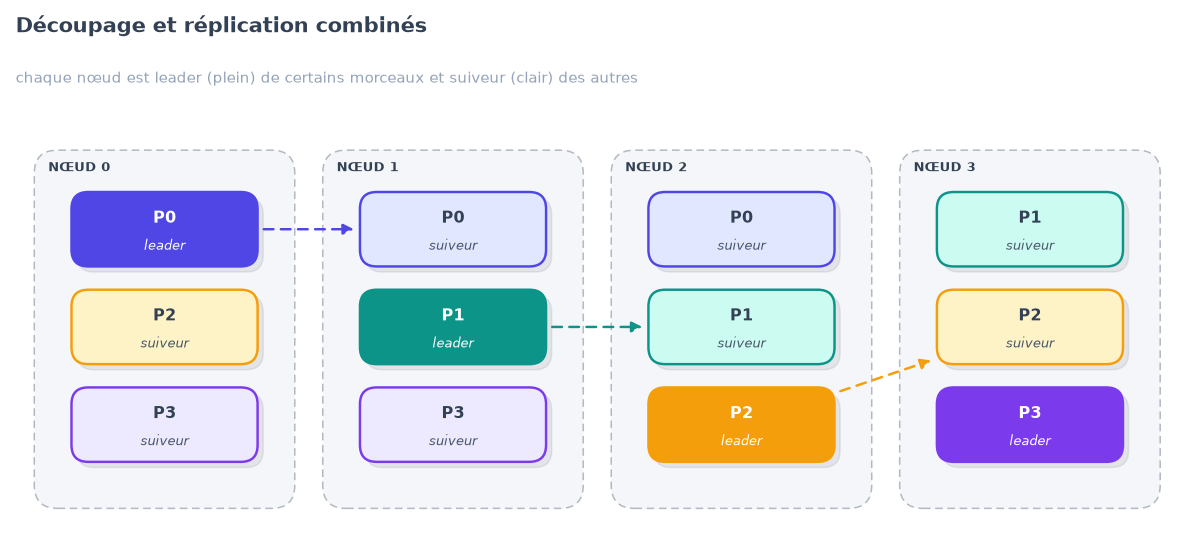

In [3]:
d = Diagram(12.6, 4.6, title="Découpage et réplication combinés",
            subtitle="chaque nœud est leader (plein) de certains morceaux et suiveur (clair) des autres")
colors = [INDIGO, TEAL, AMBER, VIOLET]
for n in range(N_NODES):
    x0 = 0.25 + n * 3.1
    d.group(x0, 0.2, x0 + 2.8, 4.05, f"nœud {n}", color=SLATE)
    row = 0
    for p in range(4):
        role = placement.iloc[p, n]
        if role:
            y = 3.2 - row * 1.05
            d.box(f"p{p}n{n}", x0 + 1.4, y, f"P{p}", sub=role, color=colors[p], w=2.0, h=0.8,
                  filled=(role == "leader"))
            row += 1
for p in range(4):
    lead = p % N_NODES
    for k in (1, 2):
        f = (lead + k) % N_NODES
        if abs(f - lead) == 1:   # flèches vers le voisin immédiat seulement, pour rester lisible
            d.arrow(f"p{p}n{lead}", f"p{p}n{f}", style="dashed", color=colors[p])
d.show()

Les flèches pointillées symbolisent le flux de réplication du leader vers un suiveur
voisin (les autres flux sont omis pour la lisibilité). Tout ce que le chapitre
5 dit de la réplication s'applique à chaque partition
séparément.

> **À retenir.** Réplication = copies identiques sur plusieurs nœuds ;
> partitionnement = morceaux disjoints sur des nœuds différents. On
> combine les deux : chaque enregistrement appartient à une seule
> partition, répliquée sur plusieurs nœuds.

## 2. L'objectif : une répartition équitable (section *Partitioning of Key-Value Data*)

**Le but.** Si chaque nœud reçoit sa juste part, 10 nœuds stockent 10 fois plus et
servent 10 fois plus de requêtes qu'un seul. Si le découpage est **déséquilibré**
(*skewed*), le gain fond : dans le cas extrême, toute la charge tombe sur un nœud et les 9
autres attendent. On appelle **point chaud** (*hot spot*) une partition
qui reçoit une charge disproportionnée, et **clé chaude** (*hot key*) une clé
particulièrement sollicitée (le compte d'une célébrité, par exemple).

**Le formaliser.** Mesurons le déséquilibre par le rapport
$\text{déséquilibre} = \max_i L_i / \bar L$ entre la charge du nœud le plus chargé et la
charge moyenne. Le cluster sature quand son nœud le plus chargé sature : le gain réel par
rapport à une machine vaut donc $n / \text{déséquilibre}$ au lieu de $n$.

Même un découpage « aléatoire » parfait laisse un déséquilibre résiduel : c'est le
problème des **balles dans des urnes**. Répartissons au hasard $K$ clés de charge égale
dans $n = 16$ partitions et mesurons le déséquilibre selon le nombre
moyen de clés par partition. Une approximation classique (loi normale
des effectifs) donne $\max/\text{moy} \approx 1 + \sqrt{2 \ln n / (K/n)}$.

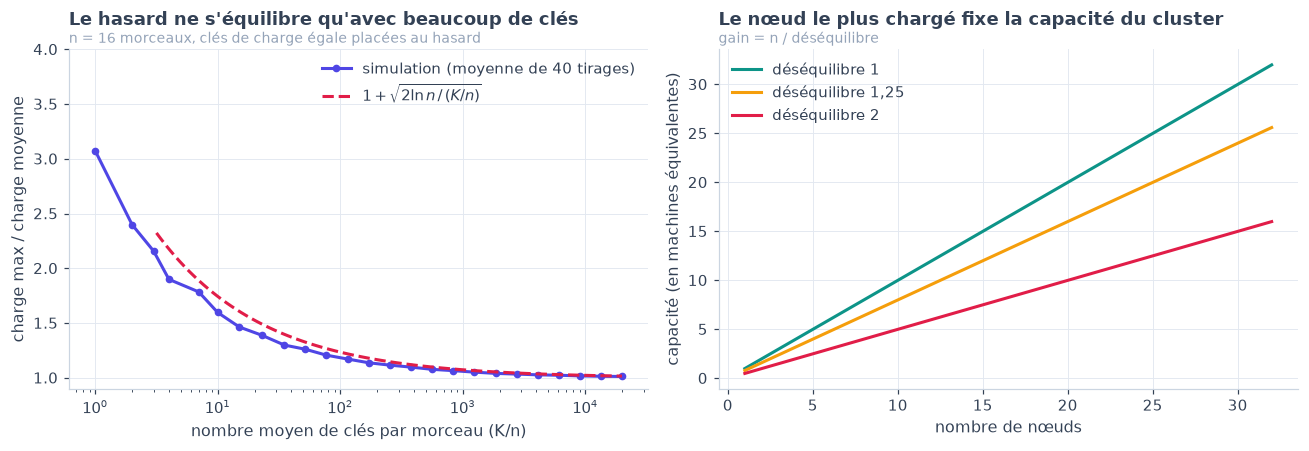

,clés par morceau,déséquilibre
0,1,3.08
5,10,1.60
10,77,1.21
15,564,1.08
20,4092,1.03


In [4]:
n = 16
per_shard = np.unique(np.logspace(0, 4.3, 26).astype(int))
rows = []
for m in per_shard:
    vals = [P.imbalance(P.shard_loads(rng.integers(0, n, m * n), n)) for _ in range(40)]
    rows.append({"clés par morceau": m, "déséquilibre": np.mean(vals)})
bib = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(bib["clés par morceau"], bib["déséquilibre"], "o-", color=INDIGO, ms=4, label="simulation (moyenne de 40 tirages)")
xs = np.logspace(0.5, 4.3, 100)
ax.plot(xs, 1 + np.sqrt(2 * np.log(n) / xs), "--", color=ROSE, label=r"$1 + \sqrt{2\ln n \,/\, (K/n)}$")
ax.set_xscale("log"); ax.set_ylim(0.9, 4)
ax.set_xlabel("nombre moyen de clés par morceau (K/n)"); ax.set_ylabel("charge max / charge moyenne")
ax.set_title("Le hasard ne s'équilibre qu'avec beaucoup de clés")
subtitle(ax, f"n = {n} morceaux, clés de charge égale placées au hasard")
ax.legend()
ax = axes[1]
for imb, c in [(1.0, TEAL), (1.25, AMBER), (2.0, ROSE)]:
    ns = np.arange(1, 33)
    ax.plot(ns, ns / imb, color=c, label=f"déséquilibre {imb:g}".replace(".", ","))
ax.set_xlabel("nombre de nœuds"); ax.set_ylabel("capacité (en machines équivalentes)")
ax.set_title("Le nœud le plus chargé fixe la capacité du cluster")
subtitle(ax, "gain = n / déséquilibre")
ax.legend()
plt.tight_layout(); plt.show()
bib.iloc[::5].round(2)

Avec quelques clés par partition, le plus chargée reçoit deux à
trois fois la moyenne ; il faut des milliers de clés par morceau pour descendre sous 5 %
d'écart. Heureusement, une base contient des millions de clés : le hasard (via une
fonction de hachage) suffit alors à équilibrer le **nombre de clés**. Ce qu'il ne règle
pas, c'est le cas où **quelques clés** concentrent la charge (cours 3), ni celui où
l'algorithme de découpage lui-même regroupe les clés actives (section 4).

> **À retenir.** Le but est de répartir données **et** requêtes uniformément ; le nœud le
> plus chargé borne la capacité du cluster (gain $n/\text{déséquilibre}$). Un placement
> aléatoire n'équilibre bien que si chaque morceau contient beaucoup de clés.

## 3. Par plage de clés (section *Partitioning by Key Range*)

**L'idée.** Attribuer à chaque partition un **intervalle contigu** de
clés, comme les volumes d'une encyclopédie papier : le volume 1 va de « A » à « Bas »,
le volume 2 de « Bat » à « Cha »... Pour trouver une entrée, il suffit de connaître les
bornes : une **recherche dichotomique** dans la liste des bornes donne le volume.

**La difficulté.** Les données ne sont pas uniformes : les mots commençant par S ou C
sont bien plus nombreux que ceux commençant par X ou Q. Des volumes de largeur fixe (deux
lettres chacun) seraient très inégaux ; il faut que les **bornes s'adaptent aux
données**. Comparons sur 30 000 titres synthétiques (initiales distribuées comme dans un
dictionnaire anglais) : 13 volumes de deux lettres contre 13 volumes bornés par les
**quantiles** des titres.

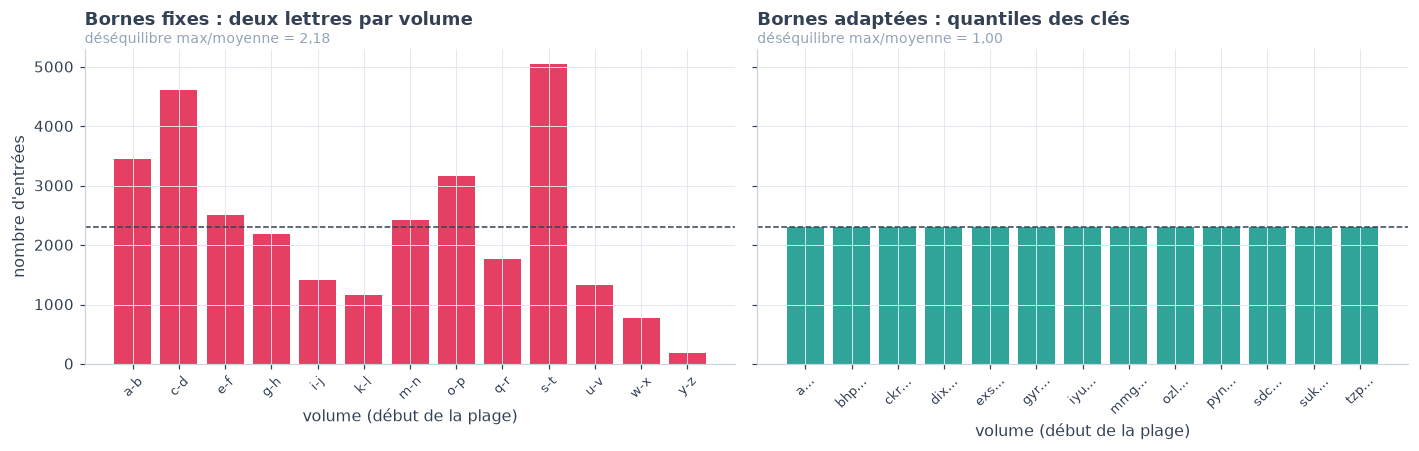

In [5]:
titles = P.synthetic_titles(30_000, seed=1)
letters = "abcdefghijklmnopqrstuvwxyz"
fixed = P.KeyRangePartitioner([letters[i] for i in range(2, 26, 2)])        # a-b, c-d, ..., y-z
adapt = P.KeyRangePartitioner.from_sample(titles, 13)
s_fixed = P.shard_loads([fixed.shard_of(t) for t in titles], 13)
s_adapt = P.shard_loads([adapt.shard_of(t) for t in titles], 13)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
lab_fixed = [f"{letters[2 * i]}-{letters[2 * i + 1]}" for i in range(13)]
b = [""] + adapt.boundaries
lab_adapt = [f"{(b[i] or 'a')[:3]}…" for i in range(13)]
for ax, s, lab, c, t in [(axes[0], s_fixed, lab_fixed, ROSE, "Bornes fixes : deux lettres par volume"),
                         (axes[1], s_adapt, lab_adapt, TEAL, "Bornes adaptées : quantiles des clés")]:
    ax.bar(range(13), s, color=c, alpha=0.85)
    ax.axhline(len(titles) / 13, color=SLATE, ls="--", lw=1)
    ax.set_xticks(range(13)); ax.set_xticklabels(lab, rotation=45, fontsize=8.5)
    ax.set_title(t)
    subtitle(ax, f"déséquilibre max/moyenne = {P.imbalance(s):.2f}".replace(".", ","))
    ax.set_xlabel("volume (début de la plage)")
axes[0].set_ylabel("nombre d'entrées")
plt.tight_layout(); plt.show()

Avec des bornes fixes, le volume « s-t » contient plus de deux fois la moyenne et le
volume « y-z » presque rien ; avec les quantiles, les 13 volumes sont égaux à une entrée
près. Les bornes peuvent être choisies **à la main** par un administrateur (Vitess,
couche de partitionnement pour MySQL) ou **automatiquement** par la
base (Bigtable, HBase, le mode par plage de MongoDB, RethinkDB, FoundationDB) :
le cours 2 montre comment elles évoluent quand les données grossissent.

**Le grand avantage : les requêtes de plage.** Dans chaque partition,
les clés sont rangées dans l'ordre (B-tree ou SSTables, chapitre 3). Toutes les
entrées qui commencent par « cha » sont donc **contiguës**, dans une seule
partition ou deux voisines : la recherche par préfixe ne touche
qu'une petite fraction du cluster.

In [6]:
def prefix_query(part, prefix):
    lo, hi = prefix, prefix + "~"          # « ~ » est après toutes les lettres en ASCII
    return part.shards_for_range(lo, hi)

for prefix in ["c", "ca", "s", "x"]:
    shards = prefix_query(adapt, prefix)
    n_hits = sum(t.startswith(prefix) for t in titles)
    print(f"préfixe {prefix!r:6} : {n_hits:5d} entrées, {len(shards)} volume(s) interrogé(s) sur 13 : {shards}")

préfixe 'c'    :  2886 entrées, 2 volume(s) interrogé(s) sur 13 : [1, 2]
préfixe 'ca'   :   101 entrées, 1 volume(s) interrogé(s) sur 13 : [1]
préfixe 's'    :  3481 entrées, 3 volume(s) interrogé(s) sur 13 : [9, 10, 11]
préfixe 'x'    :    37 entrées, 1 volume(s) interrogé(s) sur 13 : [12]


Même le préfixe « s », qui couvre près de 3 500 entrées (12 % du total), ne touche que 3
volumes sur 13 ; les préfixes plus longs n'en touchent qu'un.
On peut aussi utiliser la clé comme un **index concaténé** (chapitre 3) :
avec une clé `capteur/année-mois-jour-heure`, une seule requête de plage récupère toutes
les mesures d'un capteur sur un mois.

> **À retenir.** Par plage de clés : chaque morceau possède un intervalle contigu, les
> bornes doivent suivre la distribution des données (quantiles), et les requêtes de
> plage restent efficaces car les clés voisines sont rangées ensemble.